## Step 1 - Install & Import Libraries

In [ ]:
!pip install -q nltk scikit-learn pandas numpy matplotlib seaborn streamlit pyngrok


In [ ]:
import nltk
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

import os, re, random, warnings, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.util import ngrams
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

warnings.filterwarnings('ignore')
random.seed(42)
np.random.seed(42)
print('All setup complete!')

All setup complete!


## Step 2 - Dataset
A labeled dataset of 60 mobile game reviews across 3 classes.


In [ ]:
import os
import pandas as pd

# Unzip the manually uploaded file
!unzip -o /content/Genshin.zip

# The actual file extracted is 'genshin_review.csv'
df_raw = pd.read_csv('genshin_review.csv')

# Define a mapping function to convert 1-5 ratings to our sentiment classes
def map_sentiment(rating):
    if rating <= 2: return 'Negative'
    if rating == 3: return 'Negative'
    return 'Positive'

# Create the standard df structure using the correct column names found in the csv
df = pd.DataFrame()
df['review'] = df_raw['review'].astype(str)
df['sentiment'] = df_raw['rating'].apply(map_sentiment)

print(f'New Dataset Loaded: {len(df)} reviews')
print(df['sentiment'].value_counts().to_string())

display(df.head())

Archive:  /content/Genshin.zip
  inflating: genshin_review.csv      
New Dataset Loaded: 995 reviews
sentiment
Positive    658
Negative    337


,review,sentiment
0,Absolute Masterpiece i hate the people who gav...,Positive
1,amazing but the fandom isn't amazing,Positive
2,Very nice,Positive
3,Give me gambling money (primo gems),Positive
4,"This is one my first Open World RPG games, and...",Positive


## Step 3 - Exploratory Data Analysis

### Synthetic Data Removed
This section previously contained a manual list of 60 reviews. It has been removed to ensure the analysis strictly uses the real-world dataset loaded above.

---

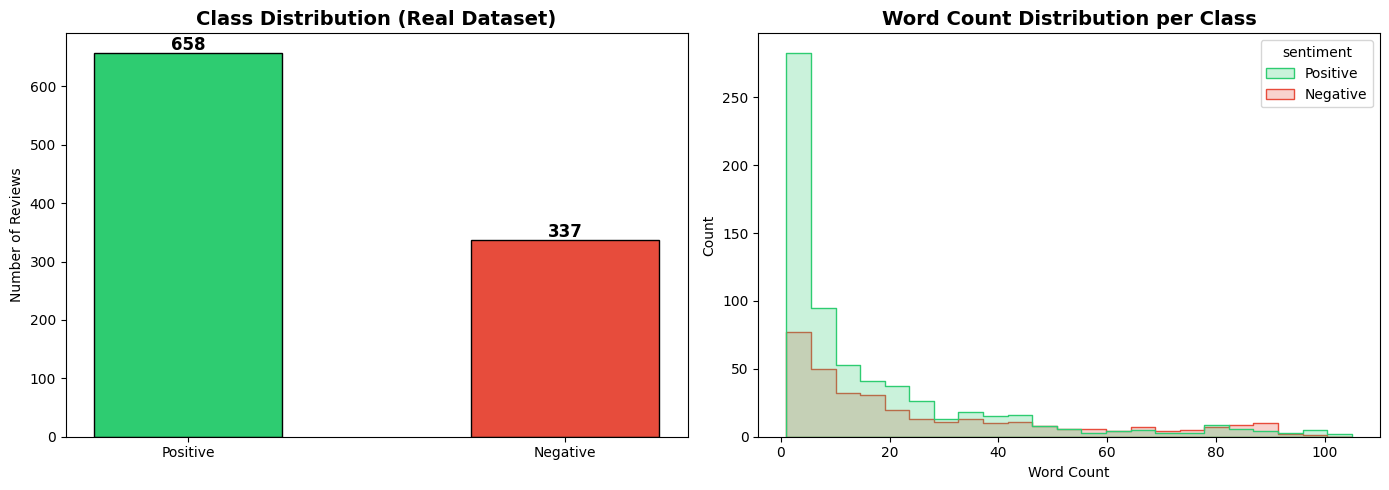

Avg words per review: 20.1


In [ ]:
df['word_count'] = df['review'].apply(lambda x: len(x.split()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors      = ['#2ecc71', '#e74c3c']
class_order = ['Positive', 'Negative']

# Left: class distribution bar chart
counts = [df[df['sentiment'] == c].shape[0] for c in class_order]
bars = axes[0].bar(class_order, counts, color=colors, edgecolor='black', width=0.5)
axes[0].set_title('Class Distribution (Real Dataset)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of Reviews')
for bar, cnt in zip(bars, counts):
    axes[0].text(bar.get_x() + bar.get_width()/2, cnt + 5, str(cnt),
                 ha='center', fontsize=12, fontweight='bold')

# Right: Word count distribution using seaborn for clarity with larger data
import seaborn as sns
sns.histplot(data=df, x='word_count', hue='sentiment', element='step',
             palette={'Positive': '#2ecc71', 'Negative': '#e74c3c'}, ax=axes[1])
axes[1].set_title('Word Count Distribution per Class', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Word Count')

plt.tight_layout()
plt.show()

print(f"Avg words per review: {df['word_count'].mean():.1f}")

## Step 4 - NLP Preprocessing Pipeline
Sentence Tokenization → Word Tokenization → Case Normalization → Punctuation Removal → Stop-word Removal → Lemmatization

In [ ]:
lemmatizer = WordNetLemmatizer()
all_sw = set(stopwords.words('english'))
keep = {'no', 'not', 'never', 'cannot', 'cant', 'dont'}
sw = all_sw - keep

def preprocess(text):
    text = text.lower()
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in sw and len(t) > 1]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return ' '.join(tokens)

df['processed'] = df['review'].apply(preprocess)

print('Preprocessing complete for 995 reviews! Sample comparisons:')
print('-' * 70)
for i in range(3):
    print(f'ORIGINAL : {df["review"].iloc[i][:100]}...')
    print(f'PROCESSED: {df["processed"].iloc[i][:100]}...')
    print('-' * 70)

Preprocessing complete for 995 reviews! Sample comparisons:
----------------------------------------------------------------------
ORIGINAL : Absolute Masterpiece i hate the people who gave this beautiful game 1 star just because you don't ha...
PROCESSED: absolute masterpiece hate people gave beautiful game star storage play mean problem...
----------------------------------------------------------------------
ORIGINAL : amazing but the fandom isn't amazing...
PROCESSED: amazing fandom amazing...
----------------------------------------------------------------------
ORIGINAL : Very nice...
PROCESSED: nice...
----------------------------------------------------------------------


## Step 5 - N-gram Analysis (Language Modeling)

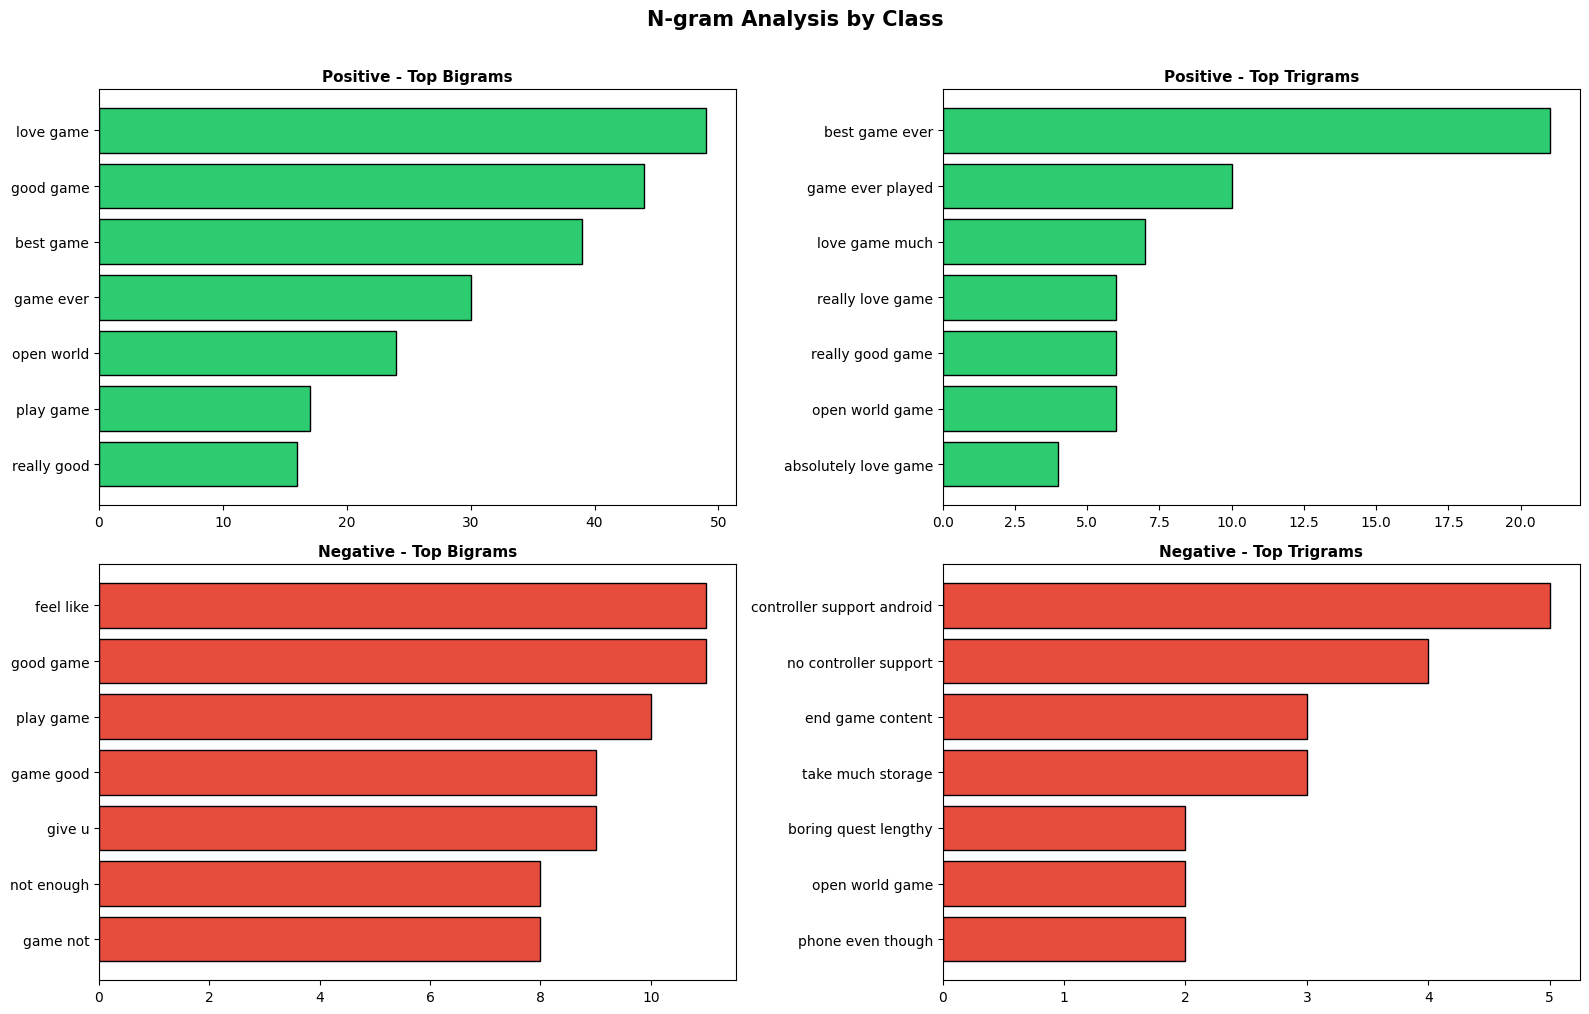

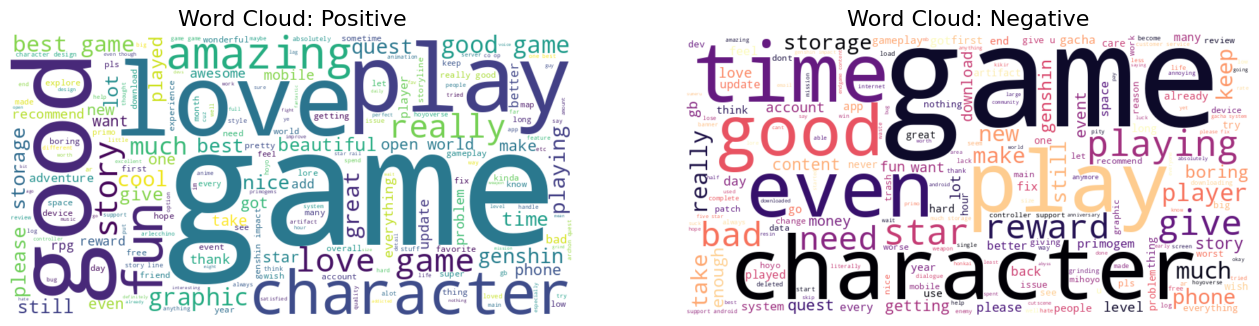

In [ ]:
from wordcloud import WordCloud

def top_ngrams(texts, n, top_k=7):
    all_ng = []
    for text in texts:
        all_ng.extend(ngrams(text.split(), n))
    return Counter(all_ng).most_common(top_k)

class_order = ['Positive', 'Negative']
colors_map  = {'Positive': '#2ecc71', 'Negative': '#e74c3c'}

# N-Gram Visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for row, cls in enumerate(class_order):
    texts = df[df['sentiment'] == cls]['processed'].tolist()
    c = colors_map[cls]
    for col_idx, (n, label) in enumerate([(2, 'Bigrams'), (3, 'Trigrams')]):
        top  = top_ngrams(texts, n)
        grams  = [' '.join(g) for g, _ in top][::-1]
        counts = [cnt for _, cnt in top][::-1]
        ax = axes[row][col_idx]
        ax.barh(grams, counts, color=c, edgecolor='black')
        ax.set_title(f'{cls} - Top {label}', fontsize=11, fontweight='bold')

plt.suptitle('N-gram Analysis by Class', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Word Cloud Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for i, cls in enumerate(class_order):
    text = " ".join(df[df['sentiment'] == cls]['processed'])
    wc = WordCloud(width=800, height=400, background_color='white',
                   colormap='viridis' if cls=='Positive' else 'magma').generate(text)
    axes[i].imshow(wc, interpolation='bilinear')
    axes[i].set_title(f'Word Cloud: {cls}', fontsize=16)
    axes[i].axis('off')
plt.show()

## Step 6 - TF-IDF Feature Extraction

In [ ]:
le = LabelEncoder()
y  = le.fit_transform(df['sentiment'])
print('Label encoding:', dict(zip(le.classes_, le.transform(le.classes_))))

X = df['processed']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f'Train: {len(X_train)} | Test: {len(X_test)}')

tfidf = TfidfVectorizer(
    ngram_range=(1, 3),
    max_features=1000,
    sublinear_tf=True,
    min_df=1
)
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec  = tfidf.transform(X_test)

print(f'Train matrix: {X_train_vec.shape}')
print(f'Test  matrix: {X_test_vec.shape}')
feat = tfidf.get_feature_names_out()
print(f'Sample features: {list(feat[:5])} ... {list(feat[-5:])}')

Label encoding: {'Negative': np.int64(0), 'Positive': np.int64(1)}
Train: 796 | Test: 199
Train matrix: (796, 1000)
Test  matrix: (199, 1000)
Sample features: ['able', 'able play', 'absolute', 'absolute best', 'absolutely'] ... ['yeah', 'year', 'year ago', 'yes', 'yet']


## Step 7 - Train Models
### Model A: Naive Bayes

In [ ]:
print('=' * 55)
print('       MODEL A: Naive Bayes')
print('=' * 55)

nb = MultinomialNB(alpha=0.5)
nb.fit(X_train_vec, y_train)
y_pred_nb = nb.predict(X_test_vec)

print(classification_report(y_test, y_pred_nb, target_names=le.classes_))

nb_acc = accuracy_score(y_test, y_pred_nb)
nb_p   = precision_score(y_test, y_pred_nb, average='weighted', zero_division=0)
nb_r   = recall_score(y_test, y_pred_nb, average='weighted', zero_division=0)
nb_f1  = f1_score(y_test, y_pred_nb, average='weighted', zero_division=0)
print(f'Accuracy : {nb_acc:.4f}')
print(f'Precision: {nb_p:.4f}')
print(f'Recall   : {nb_r:.4f}')
print(f'F1-Score : {nb_f1:.4f}')

       MODEL A: Naive Bayes
              precision    recall  f1-score   support

    Negative       0.70      0.46      0.56        67
    Positive       0.77      0.90      0.83       132

    accuracy                           0.75       199
   macro avg       0.74      0.68      0.69       199
weighted avg       0.75      0.75      0.74       199

Accuracy : 0.7538
Precision: 0.7465
Recall   : 0.7538
F1-Score : 0.7381


### Model B: SVM

In [ ]:
print('=' * 55)
print('       MODEL B: SVM (LinearSVC)')
print('=' * 55)

svm = LinearSVC(C=1.0, max_iter=2000, random_state=42)
svm.fit(X_train_vec, y_train)
y_pred_svm = svm.predict(X_test_vec)

print(classification_report(y_test, y_pred_svm, target_names=le.classes_))

svm_acc = accuracy_score(y_test, y_pred_svm)
svm_p   = precision_score(y_test, y_pred_svm, average='weighted', zero_division=0)
svm_r   = recall_score(y_test, y_pred_svm, average='weighted', zero_division=0)
svm_f1  = f1_score(y_test, y_pred_svm, average='weighted', zero_division=0)
print(f'Accuracy : {svm_acc:.4f}')
print(f'Precision: {svm_p:.4f}')
print(f'Recall   : {svm_r:.4f}')
print(f'F1-Score : {svm_f1:.4f}')

       MODEL B: SVM (LinearSVC)
              precision    recall  f1-score   support

    Negative       0.62      0.52      0.57        67
    Positive       0.78      0.84      0.81       132

    accuracy                           0.73       199
   macro avg       0.70      0.68      0.69       199
weighted avg       0.73      0.73      0.73       199

Accuracy : 0.7337
Precision: 0.7253
Recall   : 0.7337
F1-Score : 0.7271


## Step 8 - Evaluation & Comparison

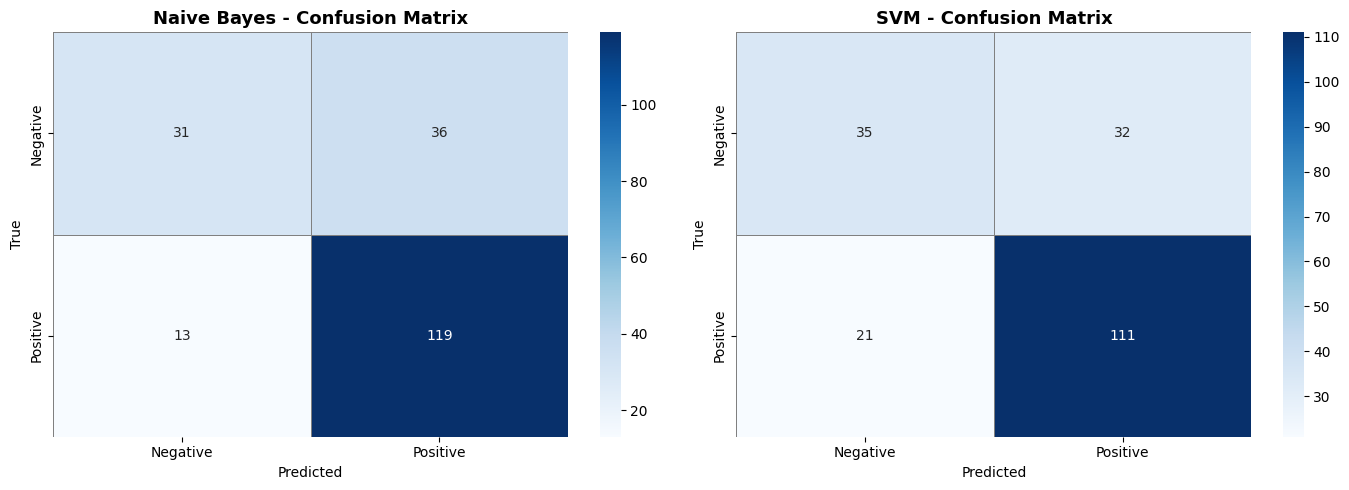

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (y_pred, title) in zip(axes, [
    (y_pred_nb,  'Naive Bayes'),
    (y_pred_svm, 'SVM')
]):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=le.classes_, yticklabels=le.classes_,
                ax=ax, linewidths=0.5, linecolor='gray')
    ax.set_title(f'{title} - Confusion Matrix', fontsize=13, fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
plt.tight_layout()
plt.show()

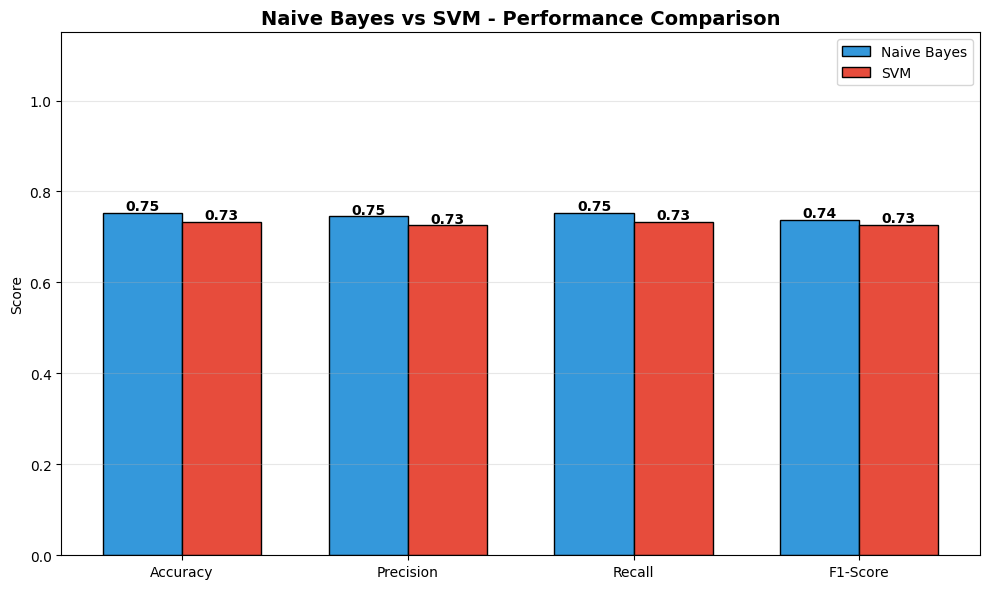

      Model  Accuracy  Precision  Recall  F1-Score
Naive Bayes    0.7538     0.7465  0.7538    0.7381
        SVM    0.7337     0.7253  0.7337    0.7271
Best Model by F1-Score: Naive Bayes


In [ ]:
metrics  = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
nb_vals  = [nb_acc,  nb_p,  nb_r,  nb_f1]
svm_vals = [svm_acc, svm_p, svm_r, svm_f1]
x     = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
b1 = ax.bar(x - width/2, nb_vals,  width, label='Naive Bayes', color='#3498db', edgecolor='black')
b2 = ax.bar(x + width/2, svm_vals, width, label='SVM',         color='#e74c3c', edgecolor='black')
for bar in list(b1) + list(b2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', fontsize=10, fontweight='bold')
ax.set_title('Naive Bayes vs SVM - Performance Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.15)
ax.set_ylabel('Score')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    'Model':     ['Naive Bayes', 'SVM'],
    'Accuracy':  [round(nb_acc,4),  round(svm_acc,4)],
    'Precision': [round(nb_p,4),    round(svm_p,4)],
    'Recall':    [round(nb_r,4),    round(svm_r,4)],
    'F1-Score':  [round(nb_f1,4),   round(svm_f1,4)],
})
print(summary.to_string(index=False))
winner = 'SVM' if svm_f1 >= nb_f1 else 'Naive Bayes'
print(f'Best Model by F1-Score: {winner}')

## Step 9 - Recurrent Neural Network (RNN) Model

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

print('TensorFlow and Keras libraries imported.')

TensorFlow and Keras libraries imported.


### Text Preprocessing for RNN

In [ ]:
# Define vocabulary size and maximum sequence length
# We'll use the preprocessed text from `df['processed']`
max_words = 10000  # Consider the top 10,000 most frequent words
max_len   = 50    # Pad sequences to a maximum length of 50 words

# Initialize and fit the tokenizer on the training data
# We will use the pre-defined X_train from the earlier TF-IDF step
tokenizer = Tokenizer(num_words=max_words, oov_token='<unk>')
tokenizer.fit_on_texts(X_train)

# Convert text to sequences of integers
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq  = tokenizer.texts_to_sequences(X_test)

# Pad sequences to ensure uniform length
X_train_padded = pad_sequences(X_train_seq, maxlen=max_len, padding='post', truncating='post')
X_test_padded  = pad_sequences(X_test_seq, maxlen=max_len, padding='post', truncating='post')

print(f'Original X_train shape: {X_train.shape}')
print(f'Padded X_train shape: {X_train_padded.shape}')
print(f'Original X_test shape: {X_test.shape}')
print(f'Padded X_test shape: {X_test_padded.shape}')

print('\nSample of padded sequence for the first training review:')
print(X_train_padded[0])

Original X_train shape: (796,)
Padded X_train shape: (796, 50)
Original X_test shape: (199,)
Padded X_test shape: (199, 50)

Sample of padded sequence for the first training review:
[  2 860  51 172 861  89 862   2 133  60 268   3  95 550  18  60   3 207
  29  20   3  95   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0]


### Build the RNN Model

In [ ]:
# Define the RNN model architecture
rnn_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=max_len),
    LSTM(128),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

# Compile the model
rnn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Display the model summary
rnn_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.layers import Bidirectional, GlobalMaxPooling1D, SpatialDropout1D
from tensorflow.keras.regularizers import l2

# Final Balanced Architecture
rnn_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=max_len),
    SpatialDropout1D(0.3),
    Bidirectional(LSTM(64, return_sequences=True, dropout=0.2, recurrent_dropout=0.2)),
    GlobalMaxPooling1D(),
    Dropout(0.4),
    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(1, activation='sigmoid')
])

# Lower learning rate for more stable convergence
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
rnn_model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
rnn_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_1             │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_1          │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

### Tips for further improvement:
* **Hyperparameters:** Try adjusting the `batch_size` (e.g., 16 or 64) or the `output_dim` of the Embedding layer.
* **Early Stopping:** You can add a callback to stop training once validation loss stops improving to prevent overfitting.
* **Data Balance:** Since your dataset is imbalanced, you could try setting `class_weight` during `.fit()` to give more importance to the 'Negative' class.

### Train the RNN Model

In [ ]:
from sklearn.utils import class_weight
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# 1. Recalculate weights
weights = class_weight.compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights_dict = {i: weights[i] for i in range(len(weights))}

# 2. Refined Callbacks for deeper search
early_stop = EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=0.00001)

# 3. Final Optimized Training - Larger batch size for stability
history = rnn_model.fit(
    X_train_padded, y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.2,
    class_weight=class_weights_dict,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

# 4. Final Evaluation
loss, accuracy = rnn_model.evaluate(X_test_padded, y_test, verbose=0)
print(f'\nFinal Tuned RNN Test Accuracy: {accuracy:.4f}')

y_pred_rnn_proba = rnn_model.predict(X_test_padded)
y_pred_rnn = (y_pred_rnn_proba > 0.5).astype('int32')

# Update global metrics
rnn_acc = accuracy
rnn_p = precision_score(y_test, y_pred_rnn, average='weighted', zero_division=0)
rnn_r = recall_score(y_test, y_pred_rnn, average='weighted', zero_division=0)
rnn_f1 = f1_score(y_test, y_pred_rnn, average='weighted', zero_division=0)

print('\n' + '=' * 55)
print('       FINAL OPTIMIZED RNN REPORT')
print('=' * 55)
print(classification_report(y_test, y_pred_rnn, target_names=le.classes_))

Epoch 1/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 32s 629ms/step - accuracy: 0.6101 - loss: 0.7676 - val_accuracy: 0.6187 - val_loss: 0.7620 - learning_rate: 0.0010
Epoch 2/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 188ms/step - accuracy: 0.6509 - loss: 0.7547 - val_accuracy: 0.6687 - val_loss: 0.7483 - learning_rate: 0.0010
Epoch 3/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 187ms/step - accuracy: 0.6022 - loss: 0.7396 - val_accuracy: 0.6938 - val_loss: 0.7379 - learning_rate: 0.0010
Epoch 4/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 181ms/step - accuracy: 0.7484 - loss: 0.7114 - val_accuracy: 0.6875 - val_loss: 0.7018 - learning_rate: 0.0010
Epoch 5/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 237ms/step - accuracy: 0.7642 - loss: 0.6563 - val_accuracy: 0.7188 - val_loss: 0.6661 - learning_rate: 0.0010
Epoch 6/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 227ms/step - accuracy: 0.8349 - loss: 0.5325 - val_accuracy: 0.7188 - val_loss: 0.6391 - learning_rate: 0.0010
Epoch 7/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 169ms/step - accuracy: 0.8695 - loss: 0.4058 -

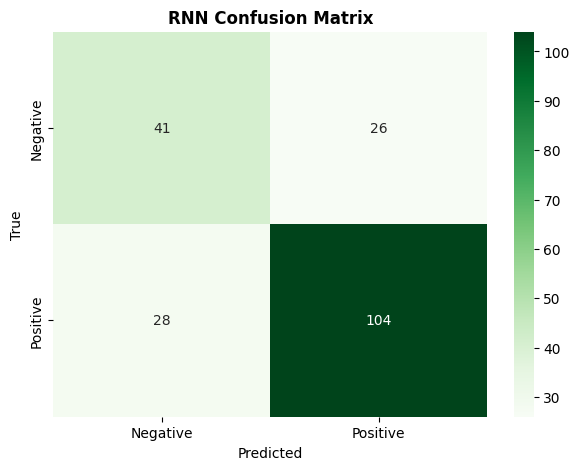

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate RNN Confusion Matrix
cm_rnn = confusion_matrix(y_test, y_pred_rnn)

plt.figure(figsize=(7, 5))
sns.heatmap(cm_rnn, annot=True, fmt='d', cmap='Greens',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('RNN Confusion Matrix', fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

In [ ]:
# Detailed Prediction Testing
test_reviews = [
    "This game is so boring and the gacha is a scam",
    "Terrible optimization, it keeps crashing on my phone",
    "I hate the greedy developers, skip this game"
]

print(f"{'Review':<50} | {'Prob':<6} | {'Class'}")
print('-' * 70)

for rev in test_reviews:
    # Preprocess using the existing tokenizer and pad logic
    seq = tokenizer.texts_to_sequences([preprocess(rev)])
    pad = pad_sequences(seq, maxlen=max_len, padding='post')

    prob = rnn_model.predict(pad, verbose=0)[0][0]
    pred_label = 'Positive' if prob > 0.5 else 'Negative'

    print(f"{rev[:48]:<50} | {prob:.3f} | {pred_label}")

Review                                             | Prob   | Class
----------------------------------------------------------------------
This game is so boring and the gacha is a scam     | 0.507 | Positive
Terrible optimization, it keeps crashing on my p   | 0.197 | Negative
I hate the greedy developers, skip this game       | 0.547 | Positive


### Comparison with other Models

                     Model  Accuracy  Precision  Recall  F1-Score
               Naive Bayes    0.7538     0.7465  0.7538    0.7381
                       SVM    0.7337     0.7253  0.7337    0.7271
Improved Bidirectional RNN    0.7286     0.7307  0.7286    0.7296


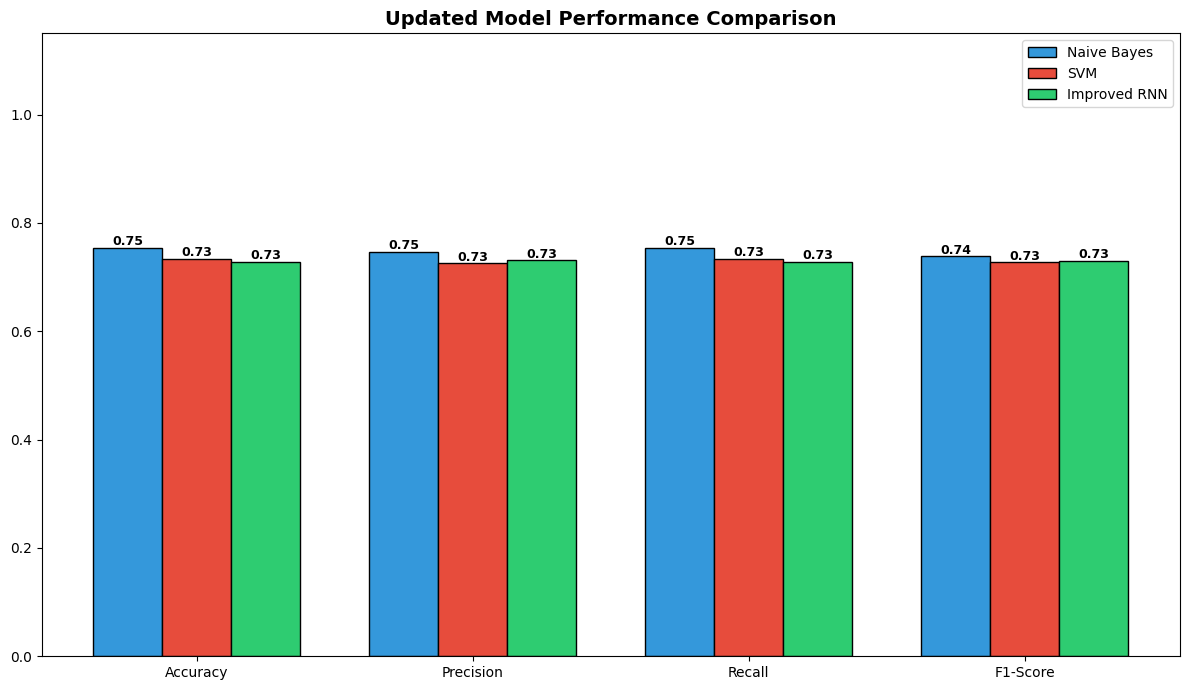

In [ ]:
# Update the summary DataFrame with the new improved RNN results
summary = pd.DataFrame({
    'Model':     ['Naive Bayes', 'SVM', 'Improved Bidirectional RNN'],
    'Accuracy':  [round(nb_acc, 4), round(svm_acc, 4), round(rnn_acc, 4)],
    'Precision': [round(nb_p, 4), round(svm_p, 4), round(rnn_p, 4)],
    'Recall':    [round(nb_r, 4), round(svm_r, 4), round(rnn_r, 4)],
    'F1-Score':  [round(nb_f1, 4), round(svm_f1, 4), round(rnn_f1, 4)],
})

print(summary.to_string(index=False))

# Visualize the updated comparison
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x = np.arange(len(metrics))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 7))
b1 = ax.bar(x - width, summary.iloc[0, 1:], width, label='Naive Bayes', color='#3498db', edgecolor='black')
b2 = ax.bar(x, summary.iloc[1, 1:], width, label='SVM', color='#e74c3c', edgecolor='black')
b3 = ax.bar(x + width, summary.iloc[2, 1:], width, label='Improved RNN', color='#2ecc71', edgecolor='black')

for bar in list(b1) + list(b2) + list(b3):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, f'{bar.get_height():.2f}', ha='center', fontsize=9, fontweight='bold')

ax.set_title('Updated Model Performance Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.15)
ax.legend()
plt.tight_layout()
plt.show()

### Comparison with other Models

## Step 10 - Streamlit Web UI
Save models first, then launch the app.

In [ ]:
with open('tfidf.pkl',         'wb') as f: pickle.dump(tfidf, f)
with open('nb_model.pkl',      'wb') as f: pickle.dump(nb,    f)
with open('svm_model.pkl',     'wb') as f: pickle.dump(svm,   f)
with open('label_encoder.pkl', 'wb') as f: pickle.dump(le,    f)
print('Models saved!')

Models saved!


In [ ]:
# Re-save the improved model for the Streamlit App
rnn_model.save('rnn_model.keras')
with open('tokenizer.pkl', 'wb') as f: pickle.dump(tokenizer, f)
print('Improved RNN model and tokenizer saved! You can now refresh the Streamlit app.')

Improved RNN model and tokenizer saved! You can now refresh the Streamlit app.


In [ ]:
app_code = """import streamlit as st
import pickle, re, nltk
import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

@st.cache_resource
def load_models():
    with open('tfidf.pkl', 'rb') as f: tfidf = pickle.load(f)
    with open('nb_model.pkl', 'rb') as f: nb = pickle.load(f)
    with open('svm_model.pkl', 'rb') as f: svm = pickle.load(f)
    with open('label_encoder.pkl', 'rb') as f: le = pickle.load(f)

    # Load RNN model and tokenizer
    rnn_model = tf.keras.models.load_model('rnn_model.keras')
    with open('tokenizer.pkl', 'rb') as f: tokenizer = pickle.load(f)
    return tfidf, nb, svm, le, rnn_model, tokenizer

tfidf, nb_model, svm_model, le, rnn_model, tokenizer = load_models()

lem = WordNetLemmatizer()
sws = set(stopwords.words('english')) - {'no', 'not', 'never', 'cannot'}

max_len = 50 # Must match the length used during RNN training

def preprocess(text, for_rnn=False):
    text = text.lower()
    text = re.sub(r'[^a-z\\s]', ' ', text)
    text = re.sub(r'\\s+', ' ', text).strip()
    tokens = word_tokenize(text)
    tokens = [lem.lemmatize(t) for t in tokens if t not in sws and len(t) > 1]
    processed_text = ' '.join(tokens)

    if for_rnn:
        # For RNN, convert to sequence and pad
        sequence = tokenizer.texts_to_sequences([processed_text])
        padded_sequence = pad_sequences(sequence, maxlen=max_len, padding='post', truncating='post')
        return padded_sequence
    return processed_text

COLORS = {'Positive': '#2ecc71', 'Negative': '#e74c3c'}

st.set_page_config(page_title='IAP Review Analyzer', page_icon='🎮', layout='centered')
st.title('IAP Frustration & Sentiment Detector')
st.markdown('**NLP Project | BS(AI) | Bahria University Islamabad**')
st.markdown('---')

model_choice = st.radio('Select Model:', ['Naive Bayes', 'SVM', 'RNN'], horizontal=True)
review_input = st.text_area('Enter Game Review:', height=140)

if st.button('Classify Review', use_container_width=True):
    if not review_input.strip():
        st.warning('Please enter a review.')
    else:
        if model_choice == 'Naive Bayes' or model_choice == 'SVM':
            processed = preprocess(review_input)
            vec = tfidf.transform([processed])
            model = nb_model if model_choice == 'Naive Bayes' else svm_model
            prediction = model.predict(vec)
        else: # RNN Model
            processed_for_rnn = preprocess(review_input, for_rnn=True)
            # RNN models return probabilities, convert to binary class
            prediction_proba = rnn_model.predict(processed_for_rnn)
            prediction = (prediction_proba > 0.5).astype('int32')

        label = le.inverse_transform(prediction)[0]
        color = COLORS.get(label, '#3498db')
        st.markdown(f'<div style="background:{color};padding:20px;border-radius:10px;color:white;text-align:center;font-size:24px;">{label}</div>', unsafe_allow_html=True)
"""

# Fix: Added encoding='utf-8' to handle emojis/special characters
with open('app.py', 'w', encoding='utf-8') as f:
    f.write(app_code)
print('app.py written successfully with UTF-8 encoding!')

app.py written successfully with UTF-8 encoding!


In [ ]:
# 1. Refresh Password/Endpoint IP
import urllib
print("Your Password/Endpoint IP is:", urllib.request.urlopen('https://ipv4.icanhazip.com').read().decode('utf8').strip())

# 2. Restart Streamlit server
!pkill streamlit
import subprocess
subprocess.Popen([
    'streamlit', 'run', 'app.py',
    '--server.port', '8501',
    '--server.headless', 'true'
])

# 3. Create a fresh tunnel link
print("Generating fresh tunnel link... Please wait.")
!ssh -o StrictHostKeyChecking=no -R 80:localhost:8501 serveo.net

Your Password/Endpoint IP is: 199.223.235.225
Generating fresh tunnel link... Please wait.
Forwarding HTTP traffic from https://94467f8855356d6a-199-223-235-225.serveousercontent.com
Tip (1): Create an account to reserve names. Pro removes the warning page: https://console.serveo.net/settings?n=1&src=ssh_nudge&v=B
Connection to serveo.net closed by remote host.
Connection to serveo.net closed.
